# Research 04 — OOF error complementarity and synthesis

This notebook combines the aligned OOF evidence from the current CatBoost/LightGBM blend, native-categorical XGBoost, and balanced CatBoost. **Predeclared hypothesis:** each weaker model may contribute a small, distinct correction, so test one fixed mixture: 80% current blend + 10% XGBoost + 10% balanced CatBoost. No weight sweep or Test access.

OOF is used repeatedly during research and model selection, so small gains on these same folds are screening evidence, not an unbiased estimate of generalization. Promote conservatively and retain the known best when the new blend does not clearly win.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import f1_score

ROOT = next(
    path for path in [Path.cwd(), *Path.cwd().parents] if (path / "data" / "train.csv").is_file()
)
base = pd.read_csv(ROOT / "predictions/segment-oof.csv")
y = base.segment.to_numpy(dtype=int)


def load_probabilities(filename):
    frame = pd.read_csv(ROOT / "predictions" / filename)
    assert len(frame) == len(base) and np.array_equal(frame.segment.to_numpy(), y), filename
    values = frame[[f"prob_{i}" for i in range(4)]].to_numpy()
    assert np.isfinite(values).all() and np.allclose(values.sum(axis=1), 1, atol=1e-5)
    return values


p_base = load_probabilities("segment-oof.csv")
p_xgb = load_probabilities("segment-xgboost-oof.csv")
p_balanced = load_probabilities("segment-balanced-catboost-oof.csv")
print(f"Aligned OOF rows: {len(y):,}")

Aligned OOF rows: 104,000


## Fixed candidates

The only new ensemble candidate is the predeclared 80/10/10 mixture. Component-only scores are included as controls. The class-prior correction is omitted because its separate notebook already showed a decline.

,candidate,macro_f1,weighted_f1
0,Current CatBoost/LightGBM,0.750895,0.764683
1,XGBoost,0.747070,0.761152
2,Balanced CatBoost,0.741759,0.753181
3,Fixed 80/10/10 mixture,0.751142,0.764884


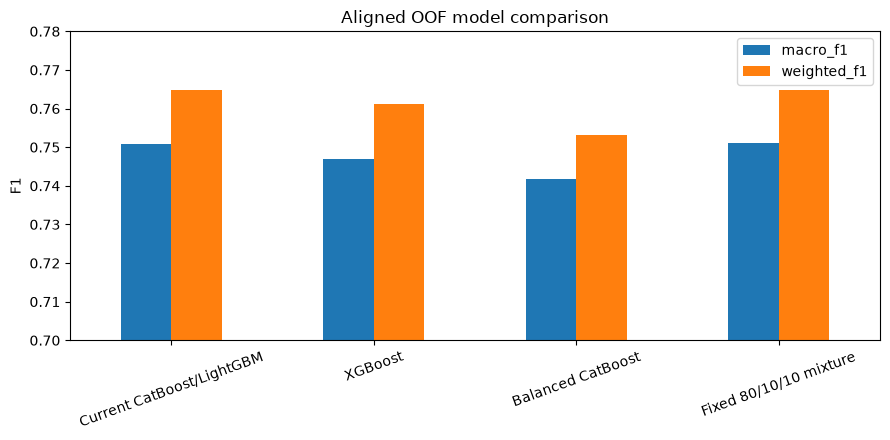

In [2]:
p_mixture = 0.8 * p_base + 0.1 * p_xgb + 0.1 * p_balanced


def score(name, probabilities):
    pred = probabilities.argmax(axis=1)
    return {
        "candidate": name,
        "macro_f1": f1_score(y, pred, average="macro"),
        "weighted_f1": f1_score(y, pred, average="weighted"),
    }


results = pd.DataFrame(
    [
        score("Current CatBoost/LightGBM", p_base),
        score("XGBoost", p_xgb),
        score("Balanced CatBoost", p_balanced),
        score("Fixed 80/10/10 mixture", p_mixture),
    ]
)
display(results)
results.to_csv(ROOT / "assets/segment-ensemble-synthesis.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
results.set_index("candidate")[["macro_f1", "weighted_f1"]].plot.bar(ax=ax, rot=20)
ax.set(title="Aligned OOF model comparison", ylabel="F1", xlabel="", ylim=(0.70, 0.78))
fig.tight_layout()
fig.savefig(ROOT / "assets/segment-ensemble-synthesis.png", dpi=300, bbox_inches="tight")
plt.show()

In [3]:
def error_complementarity(name, probabilities):
    base_correct = p_base.argmax(axis=1) == y
    model_correct = probabilities.argmax(axis=1) == y
    base_errors = ~base_correct
    return {
        "model": name,
        "base_errors_fixed": int((base_errors & model_correct).sum()),
        "base_errors_harmed": int((base_correct & ~model_correct).sum()),
        "base_error_fix_rate": float(
            (base_errors & model_correct).sum() / max(1, base_errors.sum())
        ),
    }


complementarity = pd.DataFrame(
    [
        error_complementarity("XGBoost", p_xgb),
        error_complementarity("Balanced CatBoost", p_balanced),
        error_complementarity("80/10/10 mixture", p_mixture),
    ]
)
display(complementarity)
complementarity.to_csv(ROOT / "assets/segment-error-complementarity.csv", index=False)
best = results.sort_values("macro_f1", ascending=False).iloc[0]
current = results.loc[results.candidate == "Current CatBoost/LightGBM"].iloc[0]
print(f"Best measured candidate: {best.candidate} ({best.macro_f1:.6f} macro F1)")
print(f"Delta vs current: {best.macro_f1 - current.macro_f1:+.6f}")
if best.candidate == "Current CatBoost/LightGBM" or best.macro_f1 <= current.macro_f1:
    print("Decision: retain current; no test prediction generated.")
else:
    print(
        "Screening gain only. Confirm with a fresh split or another independent validation before promotion."
    )

,model,base_errors_fixed,base_errors_harmed,base_error_fix_rate
0,XGBoost,2082,2474,0.085725
1,Balanced CatBoost,3730,5235,0.153580
2,80/10/10 mixture,420,429,0.017293


Best measured candidate: Fixed 80/10/10 mixture (0.751142 macro F1)
Delta vs current: +0.000247
Screening gain only. Confirm with a fresh split or another independent validation before promotion.


## Interpretation

This combines saved OOF predictions row-for-row, verifies identical target ordering, and keeps Test untouched. A weaker model is useful only if its errors are sufficiently complementary and the fixed mixture beats the current model. No Kaggle submission is generated here. Its `player_id` predictions map to `ANS` ids by test row position when a submission is built.